In [1]:
import os, tarfile, gzip
import pandas as pd

data_dir = os.path.expanduser("~/FYP_Regeneration/data/human_sc/")
tar_path = os.path.join(data_dir, "GSE241132_RAW.tar")
meta_path = os.path.join(data_dir, "GSE241132_cell_metadata.txt.gz")

print("RAW.tar exists:", os.path.exists(tar_path))
print("metadata exists:", os.path.exists(meta_path))

with tarfile.open(tar_path) as tar:
    members = tar.getmembers()
    for m in members[:20]:
        print(f"{m.size/1e6:8.1f} MB  {m.name}")
    print(f"... {len(members)} files total")
    tar.extractall(data_dir)

print("\n--- Cell metadata preview ---")
meta = pd.read_csv(meta_path, sep="\t", compression="gzip", nrows=5)
print("Columns:", list(meta.columns))
print(meta.head())

meta_full = pd.read_csv(meta_path, sep="\t", compression="gzip")
print(f"\nTotal cells in metadata: {len(meta_full)}")
for col in meta_full.columns:
    if meta_full[col].nunique() < 30:
        print(f"\n{col} value counts:")
        print(meta_full[col].value_counts())

RAW.tar exists: True
metadata exists: True
    51.2 MB  GSM7717079_PWH26D0.zip
    64.9 MB  GSM7717080_PWH26D1.zip
    66.3 MB  GSM7717081_PWH26D7.zip
    41.9 MB  GSM7717082_PWH26D30.zip
    42.4 MB  GSM7717083_PWH27D0.zip
    83.4 MB  GSM7717084_PWH27D1.zip
    92.0 MB  GSM7717085_PWH27D7.zip
    75.7 MB  GSM7717086_PWH27D30.zip
    49.3 MB  GSM7717087_PWH28D0.zip
    68.3 MB  GSM7717088_PWH28D1.zip
    75.3 MB  GSM7717089_PWH28D7.zip
    65.3 MB  GSM7717090_PWH28D30.zip
... 12 files total

--- Cell metadata preview ---
Columns: ['barcode', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'Patient', 'Gender', 'Age', 'Condition', 'Doublet', 'doublet_scores', 'percent.mt', 'percent.ribo', 'percent.hb', 'percent.malat1', 'S.Score', 'G2M.Score', 'Phase', 'CC.Difference', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.5', 'seurat_clusters', 'SCT_snn_res.0.8', 'oldCellTypes_InATACproject', 'newCellTypes', 'newMainCellTypes']
                      barcode orig.ident  nCount_RNA  nFeature_RNA Patie

In [2]:
import zipfile

data_dir = os.path.expanduser("~/FYP_Regeneration/data/human_sc/")
sample_zip = os.path.join(data_dir, "GSM7717079_PWH26D0.zip")

with zipfile.ZipFile(sample_zip) as z:
    for name in z.namelist():
        print(name)

PWH26D0/
PWH26D0/PWH26D0_matrix.mtx.gz
__MACOSX/PWH26D0/._PWH26D0_matrix.mtx.gz
PWH26D0/PWH26D0_features.tsv.gz
__MACOSX/PWH26D0/._PWH26D0_features.tsv.gz
PWH26D0/PWH26D0_barcodes.tsv.gz
__MACOSX/PWH26D0/._PWH26D0_barcodes.tsv.gz


In [3]:
import zipfile
import glob

data_dir = os.path.expanduser("~/FYP_Regeneration/data/human_sc/")
zip_files = sorted(glob.glob(os.path.join(data_dir, "GSM*.zip")))
print(f"Found {len(zip_files)} zip files")

for zf in zip_files:
    with zipfile.ZipFile(zf) as z:
        # skip macOS junk, keep only real sample files
        for name in z.namelist():
            if "__MACOSX" not in name and not os.path.basename(name).startswith("._"):
                z.extract(name, data_dir)

print("Extraction done. Sample folders:")
for d in sorted(os.listdir(data_dir)):
    full = os.path.join(data_dir, d)
    if os.path.isdir(full) and "MACOSX" not in d:
        print(" ", d, os.listdir(full))

Found 12 zip files
Extraction done. Sample folders:
  PWH26D0 ['PWH26D0_matrix.mtx.gz', 'PWH26D0_features.tsv.gz', 'PWH26D0_barcodes.tsv.gz']
  PWH26D1 ['PWH26D1_features.tsv.gz', 'PWH26D1_barcodes.tsv.gz', 'PWH26D1_matrix.mtx.gz']
  PWH26D30 ['PWH26D30_features.tsv.gz', 'PWH26D30_barcodes.tsv.gz', 'PWH26D30_matrix.mtx.gz']
  PWH26D7 ['PWH26D7_matrix.mtx.gz', 'PWH26D7_barcodes.tsv.gz', 'PWH26D7_features.tsv.gz']
  PWH27D0 ['PWH27D0_features.tsv.gz', 'PWH27D0_barcodes.tsv.gz', 'PWH27D0_matrix.mtx.gz']
  PWH27D1 ['PWH27D1_barcodes.tsv.gz', 'PWH27D1_matrix.mtx.gz', 'PWH27D1_features.tsv.gz']
  PWH27D30 ['PWH27D30_features.tsv.gz', 'PWH27D30_barcodes.tsv.gz', 'PWH27D30_matrix.mtx.gz']
  PWH27D7 ['PWH27D7_features.tsv.gz', 'PWH27D7_barcodes.tsv.gz', 'PWH27D7_matrix.mtx.gz']
  PWH28D0 ['PWH28D0_matrix.mtx.gz', 'PWH28D0_features.tsv.gz', 'PWH28D0_barcodes.tsv.gz']
  PWH28D1 ['PWH28D1_features.tsv.gz', 'PWH28D1_matrix.mtx.gz', 'PWH28D1_barcodes.tsv.gz']
  PWH28D30 ['PWH28D30_barcodes.tsv.gz', 

In [2]:
import os, glob, gzip
import pandas as pd
import scipy.io
import anndata as ad
import scanpy as sc

data_dir = os.path.expanduser("~/FYP_Regeneration/data/human_sc/")
meta_path = os.path.join(data_dir, "GSE241132_cell_metadata.txt.gz")

# Extraction already happened last session — this just confirms folders exist,
# safe to re-run even if some sessions already did it (harmless if skipped)
zip_files = sorted(glob.glob(os.path.join(data_dir, "GSM*.zip")))
for zf in zip_files:
    import zipfile
    with zipfile.ZipFile(zf) as z:
        for name in z.namelist():
            if "__MACOSX" not in name and not os.path.basename(name).startswith("._"):
                if not os.path.exists(os.path.join(data_dir, name)):
                    z.extract(name, data_dir)
print("Sample folders confirmed present.")

meta = pd.read_csv(meta_path, sep="\t", compression="gzip")
meta = meta.set_index("barcode")
print(f"Metadata: {len(meta)} QC-passed singlet cells")

def load_10x_manual(sample_dir, prefix):
    with gzip.open(os.path.join(sample_dir, f"{prefix}_matrix.mtx.gz"), "rb") as f:
        mat = scipy.io.mmread(f).tocsr().T
    genes = pd.read_csv(os.path.join(sample_dir, f"{prefix}_features.tsv.gz"),
                         sep="\t", header=None)
    gene_symbols = genes.iloc[:, 1].values if genes.shape[1] > 1 else genes.iloc[:, 0].values
    barcodes = pd.read_csv(os.path.join(sample_dir, f"{prefix}_barcodes.tsv.gz"),
                            sep="\t", header=None)[0].values
    a = ad.AnnData(X=mat)
    a.var_names = pd.Index(gene_symbols).astype(str)
    a.obs_names = barcodes
    return a

sample_ids = ["PWH26D0","PWH26D1","PWH26D7","PWH26D30",
              "PWH27D0","PWH27D1","PWH27D7","PWH27D30",
              "PWH28D0","PWH28D1","PWH28D7","PWH28D30"]

fib_adatas = []
for sid in sample_ids:
    sample_dir = os.path.join(data_dir, sid)
    a = load_10x_manual(sample_dir, sid)
    a.obs_names = [f"{sid}_{bc}" for bc in a.obs_names]

    keep = a.obs_names.isin(meta.index)
    a = a[keep].copy()
    a.obs["Condition"] = meta.loc[a.obs_names, "Condition"].values
    a.obs["newMainCellTypes"] = meta.loc[a.obs_names, "newMainCellTypes"].values
    a.obs["Patient"] = meta.loc[a.obs_names, "Patient"].values

    a_fib = a[a.obs["newMainCellTypes"] == "Fibroblast"].copy()
    a_fib.var_names_make_unique()
    fib_adatas.append(a_fib)
    print(f"{sid}: {a.n_obs} QC-passed cells -> {a_fib.n_obs} fibroblasts")

human_fib = ad.concat(fib_adatas, join="outer")
human_fib.var_names_make_unique()
print(f"\nTotal fibroblasts: {human_fib.n_obs} x {human_fib.n_vars} genes")
print(human_fib.obs["Condition"].value_counts())

out_dir = os.path.expanduser("~/FYP_Regeneration/data/human_sc/processed/")
os.makedirs(out_dir, exist_ok=True)
human_fib.write(os.path.join(out_dir, "human_fibroblast_only.h5ad"))
print("Saved.")

Sample folders confirmed present.
Metadata: 58823 QC-passed singlet cells


/home/ghayyas/miniconda3/envs/axolotl_regen/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/ghayyas/miniconda3/envs/axolotl_regen/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


PWH26D0: 4242 QC-passed cells -> 724 fibroblasts


/home/ghayyas/miniconda3/envs/axolotl_regen/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/ghayyas/miniconda3/envs/axolotl_regen/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


PWH26D1: 4709 QC-passed cells -> 255 fibroblasts


...

PWH28D1: 4578 QC-passed cells -> 260 fibroblasts


/home/ghayyas/miniconda3/envs/axolotl_regen/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/ghayyas/miniconda3/envs/axolotl_regen/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


PWH28D7: 5358 QC-passed cells -> 909 fibroblasts


/home/ghayyas/miniconda3/envs/axolotl_regen/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/ghayyas/miniconda3/envs/axolotl_regen/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


PWH28D30: 5735 QC-passed cells -> 2335 fibroblasts

Total fibroblasts: 12259 x 36600 genes
Condition
Wound30    5274
Wound7     3821
Skin       2152
Wound1     1012
Name: count, dtype: int64
Saved.


In [3]:
human_fib.obs["regen_status"] = human_fib.obs["Condition"].map(
    lambda x: "Uninjured" if x == "Skin" else "Regenerating"
)
print(human_fib.obs["regen_status"].value_counts())

human_fib.layers["counts"] = human_fib.X.copy()
sc.pp.normalize_total(human_fib, target_sum=1e4)
sc.pp.log1p(human_fib)

sc.tl.rank_genes_groups(
    human_fib, "regen_status",
    groups=["Regenerating"], reference="Uninjured",
    method="wilcoxon"
)

result = human_fib.uns["rank_genes_groups"]
de_df = pd.DataFrame({
    "gene": result["names"]["Regenerating"],
    "logfoldchanges": result["logfoldchanges"]["Regenerating"],
    "pvals_adj": result["pvals_adj"]["Regenerating"],
})

tables_dir = os.path.expanduser("~/FYP_Regeneration/results/tables/")
os.makedirs(tables_dir, exist_ok=True)
de_df.to_csv(os.path.join(tables_dir, "human_fibroblast_wound_vs_skin_all.csv"), index=False)

sig_df = de_df[(de_df["pvals_adj"] < 0.05) & (de_df["logfoldchanges"].abs() > 1.0)]
print(f"\nSignificant genes: {len(sig_df)}")
print(sig_df.head(15))

regen_status
Regenerating    10107
Uninjured        2152
Name: count, dtype: int64

Significant genes: 3261
       gene  logfoldchanges  pvals_adj
0      NME2        1.772732        0.0
1      PPIB        2.037681        0.0
2     GAPDH        1.757811        0.0
3   S100A11        1.759823        0.0
4       MIF        1.617953        0.0
5     SERF2        1.543485        0.0
6    ARPC1B        2.381710        0.0
7    TMSB10        1.197127        0.0
8      OSTC        2.055458        0.0
9     PRDX4        2.889238        0.0
10     SSR4        1.663145        0.0
11     CD63        1.158717        0.0
12   SEC61B        1.453632        0.0
13     THY1        2.637649        0.0
15      FAP        3.038083        0.0


In [4]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from pybiomart import Server
import os

tables_dir = os.path.expanduser("~/FYP_Regeneration/results/tables/")

ax_all = pd.read_csv(os.path.join(tables_dir, "axolotl_regen_vs_uninjured_all.csv"))
ms_all = pd.read_csv(os.path.join(tables_dir, "mouse_sc_fibroblast_regen_vs_uninjured_all.csv"))
hu_all = pd.read_csv(os.path.join(tables_dir, "human_fibroblast_wound_vs_skin_all.csv"))

ax_all["gene_upper"] = ax_all["gene"].astype(str).str.upper()
ms_all["gene_upper"] = ms_all["gene"].astype(str).str.upper()
hu_all["gene_upper"] = hu_all["gene"].astype(str).str.upper()

server = Server(host="http://www.ensembl.org")
ds = server.marts["ENSEMBL_MART_ENSEMBL"].datasets["mmusculus_gene_ensembl"]
hom = ds.query(attributes=["external_gene_name", "hsapiens_homolog_associated_gene_name"]).dropna()
hom.columns = ["mouse_symbol", "human_ortholog"]
hom["mouse_symbol"] = hom["mouse_symbol"].str.upper()
hom["human_ortholog"] = hom["human_ortholog"].str.upper()
m2h = dict(zip(hom["mouse_symbol"], hom["human_ortholog"]))

ms_all["human_ortholog"] = ms_all["gene_upper"].map(m2h)
ms_mapped = ms_all.dropna(subset=["human_ortholog"])[["human_ortholog","logfoldchanges"]]
ms_mapped = ms_mapped.rename(columns={"human_ortholog":"gene_upper", "logfoldchanges":"ms_lfc"})

def permutation_spearman(x, y, n_perm=10000, seed=42):
    rho, p_param = spearmanr(x, y)
    rng = np.random.default_rng(seed)
    null = np.zeros(n_perm)
    y_arr = np.array(y)
    for i in range(n_perm):
        null[i], _ = spearmanr(x, rng.permutation(y_arr))
    p_emp = (np.sum(np.abs(null) >= np.abs(rho)) + 1) / (n_perm + 1)
    return rho, p_param, p_emp

# Axolotl vs Human
m_ax_hu = pd.merge(
    ax_all[["gene_upper","logfoldchanges"]].rename(columns={"logfoldchanges":"ax_lfc"}),
    hu_all[["gene_upper","logfoldchanges"]].rename(columns={"logfoldchanges":"hu_lfc"}),
    on="gene_upper", how="inner"
).replace([np.inf,-np.inf], np.nan).dropna()
rho_ah, p_param_ah, p_emp_ah = permutation_spearman(m_ax_hu["ax_lfc"], m_ax_hu["hu_lfc"])
print(f"Axolotl-Human:  n={len(m_ax_hu)}, rho={rho_ah:.4f}, param_p={p_param_ah:.3g}, perm_p={p_emp_ah:.4g}")

# Mouse vs Human
m_ms_hu = pd.merge(
    ms_mapped,
    hu_all[["gene_upper","logfoldchanges"]].rename(columns={"logfoldchanges":"hu_lfc"}),
    on="gene_upper", how="inner"
).replace([np.inf,-np.inf], np.nan).dropna()
rho_mh, p_param_mh, p_emp_mh = permutation_spearman(m_ms_hu["ms_lfc"], m_ms_hu["hu_lfc"])
print(f"Mouse-Human:    n={len(m_ms_hu)}, rho={rho_mh:.4f}, param_p={p_param_mh:.3g}, perm_p={p_emp_mh:.4g}")

print(f"\nAxolotl-Mouse (from earlier run): n=11544, rho=0.0845, param_p=9.83e-20, perm_p<0.0001")

summary = pd.DataFrame([
    {"Comparison": "Axolotl-Mouse (regen vs regen)", "n": 11544, "rho": 0.0845, "perm_p": "<0.0001"},
    {"Comparison": "Axolotl-Human (regen vs scar)",  "n": len(m_ax_hu), "rho": rho_ah, "perm_p": p_emp_ah},
    {"Comparison": "Mouse-Human (regen vs scar)",     "n": len(m_ms_hu), "rho": rho_mh, "perm_p": p_emp_mh},
])
print("\n=== Specificity Test Summary ===")
print(summary.to_string(index=False))
summary.to_csv(os.path.join(tables_dir, "specificity_test_summary.csv"), index=False)

Axolotl-Human:  n=11777, rho=0.1181, param_p=7.34e-38, perm_p=9.999e-05
Mouse-Human:    n=16956, rho=0.1410, param_p=4.81e-76, perm_p=9.999e-05

Axolotl-Mouse (from earlier run): n=11544, rho=0.0845, param_p=9.83e-20, perm_p<0.0001

=== Specificity Test Summary ===
                    Comparison     n      rho  perm_p
Axolotl-Mouse (regen vs regen) 11544 0.084500 <0.0001
 Axolotl-Human (regen vs scar) 11777 0.118120  0.0001
   Mouse-Human (regen vs scar) 16956 0.141023  0.0001


In [5]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

# Standard cell-cycle gene list (Tirosh et al. 2015 / Scanpy's built-in set)
s_genes = ["MCM5","PCNA","TYMS","FEN1","MCM2","MCM4","RRM1","UNG","GINS2","MCM6",
           "CDCA7","DTL","PRIM1","UHRF1","MLF1IP","HELLS","RFC2","RPA2","NASP",
           "RAD51AP1","GMNN","WDR76","SLBP","CCNE2","UBR7","POLD3","MSH2","ATAD2",
           "RAD51","RRM2","CDC45","CDC6","EXO1","TIPIN","DSCC1","BLM","CASP8AP2",
           "USP1","CLSPN","POLA1","CHAF1B","BRIP1","E2F8"]
g2m_genes = ["HMGB2","CDK1","NUSAP1","UBE2C","BIRC5","TPX2","TOP2A","NDC80",
             "CKS2","NUF2","CKS1B","MKI67","TMPO","CENPF","TACC3","FAM64A",
             "SMC4","CCNB2","CKAP2L","CKAP2","AURKB","BUB1","KIF11","ANP32E",
             "TUBB4B","GTSE1","KIF20B","HJURP","CDCA3","HN1","CDC20","TTK",
             "CDC25C","KIF2C","RANGAP1","NCAPD2","DLGAP5","CDCA2","CDCA8",
             "ECT2","KIF23","HMMR","AURKA","PSRC1","ANLN","LBR","CKAP5",
             "CENPE","CTCF","NEK2","G2E3","GAS2L3","CBX5","CENPA"]
cell_cycle_genes = set(s_genes) | set(g2m_genes)

tables_dir = os.path.expanduser("~/FYP_Regeneration/results/tables/")
ax_all = pd.read_csv(os.path.join(tables_dir, "axolotl_regen_vs_uninjured_all.csv"))
ms_all = pd.read_csv(os.path.join(tables_dir, "mouse_sc_fibroblast_regen_vs_uninjured_all.csv"))
hu_all = pd.read_csv(os.path.join(tables_dir, "human_fibroblast_wound_vs_skin_all.csv"))

for df in [ax_all, ms_all, hu_all]:
    df["gene_upper"] = df["gene"].astype(str).str.upper()

ax_noCC = ax_all[~ax_all["gene_upper"].isin(cell_cycle_genes)]
ms_noCC = ms_all[~ms_all["gene_upper"].isin(cell_cycle_genes)]
hu_noCC = hu_all[~hu_all["gene_upper"].isin(cell_cycle_genes)]

print(f"Removed cell-cycle genes: axolotl {len(ax_all)-len(ax_noCC)}, "
      f"mouse {len(ms_all)-len(ms_noCC)}, human {len(hu_all)-len(hu_noCC)}")

def permutation_spearman(x, y, n_perm=10000, seed=42):
    rho, p_param = spearmanr(x, y)
    rng = np.random.default_rng(seed)
    null = np.zeros(n_perm)
    y_arr = np.array(y)
    for i in range(n_perm):
        null[i], _ = spearmanr(x, rng.permutation(y_arr))
    p_emp = (np.sum(np.abs(null) >= np.abs(rho)) + 1) / (n_perm + 1)
    return rho, p_param, p_emp

m_ax_ms = pd.merge(
    ax_noCC[["gene_upper","logfoldchanges"]].rename(columns={"logfoldchanges":"ax_lfc"}),
    ms_noCC[["gene_upper","logfoldchanges"]].rename(columns={"logfoldchanges":"ms_lfc"}),
    on="gene_upper", how="inner"
).replace([np.inf,-np.inf], np.nan).dropna()
rho, p_param, p_emp = permutation_spearman(m_ax_ms["ax_lfc"], m_ax_ms["ms_lfc"])
print(f"\nAxolotl-Mouse (no cell-cycle genes): n={len(m_ax_ms)}, rho={rho:.4f}, perm_p={p_emp:.4g}")
print(f"(Original, with cell-cycle genes: n=11544, rho=0.0845)")

Removed cell-cycle genes: axolotl 92, mouse 94, human 94

Axolotl-Mouse (no cell-cycle genes): n=11454, rho=0.0772, perm_p=9.999e-05
(Original, with cell-cycle genes: n=11544, rho=0.0845)


In [6]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

tables_dir = os.path.expanduser("~/FYP_Regeneration/results/tables/")
ax_all = pd.read_csv(os.path.join(tables_dir, "axolotl_regen_vs_uninjured_all.csv"))
ms_all = pd.read_csv(os.path.join(tables_dir, "mouse_sc_fibroblast_regen_vs_uninjured_all.csv"))
ax_all["gene_upper"] = ax_all["gene"].astype(str).str.upper()
ms_all["gene_upper"] = ms_all["gene"].astype(str).str.upper()

ax_dup_count = ax_all["gene_upper"].duplicated(keep=False).sum()
ms_dup_count = ms_all["gene_upper"].duplicated(keep=False).sum()
print(f"Duplicated gene symbols: axolotl={ax_dup_count}, mouse={ms_dup_count}")

# Keep only symbols appearing exactly once in each species' table = unambiguous 1:1 matches
ax_unique = ax_all[~ax_all["gene_upper"].duplicated(keep=False)]
ms_unique = ms_all[~ms_all["gene_upper"].duplicated(keep=False)]

merged_1to1 = pd.merge(
    ax_unique[["gene_upper","logfoldchanges"]].rename(columns={"logfoldchanges":"ax_lfc"}),
    ms_unique[["gene_upper","logfoldchanges"]].rename(columns={"logfoldchanges":"ms_lfc"}),
    on="gene_upper", how="inner"
).replace([np.inf,-np.inf], np.nan).dropna()

print(f"Genes remaining after 1:1 restriction: {len(merged_1to1)} (was 11,544)")

def permutation_spearman(x, y, n_perm=10000, seed=42):
    rho, p_param = spearmanr(x, y)
    rng = np.random.default_rng(seed)
    null = np.zeros(n_perm)
    y_arr = np.array(y)
    for i in range(n_perm):
        null[i], _ = spearmanr(x, rng.permutation(y_arr))
    p_emp = (np.sum(np.abs(null) >= np.abs(rho)) + 1) / (n_perm + 1)
    return rho, p_param, p_emp

rho, p_param, p_emp = permutation_spearman(merged_1to1["ax_lfc"], merged_1to1["ms_lfc"])
print(f"\n1:1-restricted Axolotl-Mouse: rho={rho:.4f}, param_p={p_param:.3g}, perm_p={p_emp:.4g}")
print(f"(Full set: rho=0.0845 | No-cell-cycle: rho=0.0772)")

merged_1to1.to_csv(os.path.join(tables_dir, "axolotl_mouse_1to1_correlation.csv"), index=False)

Duplicated gene symbols: axolotl=0, mouse=0
Genes remaining after 1:1 restriction: 11544 (was 11,544)

1:1-restricted Axolotl-Mouse: rho=0.0845, param_p=9.83e-20, perm_p=9.999e-05
(Full set: rho=0.0845 | No-cell-cycle: rho=0.0772)


In [7]:
import os
import pandas as pd
import gseapy as gp

tables_dir = os.path.expanduser("~/FYP_Regeneration/results/tables/")

# Save the human sig file that was never written
hu_all = pd.read_csv(os.path.join(tables_dir, "human_fibroblast_wound_vs_skin_all.csv"))
hu_sig = hu_all[(hu_all["pvals_adj"] < 0.05) & (hu_all["logfoldchanges"].abs() > 1.0)]
hu_sig.to_csv(os.path.join(tables_dir, "human_fibroblast_wound_vs_skin_sig.csv"), index=False)
print(f"Human significant genes saved: {len(hu_sig)}")

# Rerun pathway enrichment on the CURRENT, final gene sets
ax = pd.read_csv(os.path.join(tables_dir, "axolotl_regen_vs_uninjured_sig.csv"))
ms = pd.read_csv(os.path.join(tables_dir, "mouse_sc_fibroblast_regen_vs_uninjured_sig.csv"))

gene_sets_final = {
    "Axolotl": sorted(set(ax["gene"].dropna().astype(str).str.upper())),
    "Mouse": sorted(set(ms["gene"].dropna().astype(str).str.upper())),
    "Human": sorted(set(hu_sig["gene"].dropna().astype(str).str.upper())),
}
for name, genes in gene_sets_final.items():
    print(f"{name}: {len(genes)} genes")

libs = ["GO_Biological_Process_2023", "KEGG_2021_Human", "Reactome_2022"]
sig_terms_final = {}
for name, genes in gene_sets_final.items():
    enr = gp.enrichr(gene_list=genes, gene_sets=libs, organism="human", outdir=None)
    df = enr.results
    df = df[df["Adjusted P-value"] < 0.05].sort_values("Adjusted P-value")
    df.to_csv(os.path.join(tables_dir, f"pathways_{name.lower()}_FINAL.csv"), index=False)
    sig_terms_final[name] = df.set_index("Term")
    print(f"{name}: -> {len(df)} significant pathways")

ax_t, ms_t, hu_t = (set(sig_terms_final[k].index) for k in ["Axolotl", "Mouse", "Human"])
print(f"\nAxolotl & Mouse shared: {len(ax_t & ms_t)}")
print(f"Axolotl & Human shared: {len(ax_t & hu_t)}")
print(f"Mouse & Human shared: {len(ms_t & hu_t)}")
print(f"All three shared: {len(ax_t & ms_t & hu_t)}")
print("\nAxolotl & Mouse shared pathways (this is your updated headline pathway result):")
for t in sorted(ax_t & ms_t):
    print(" -", t)

shared_df = pd.DataFrame({"Term": sorted(ax_t | ms_t | hu_t)})
shared_df["Axolotl"] = shared_df["Term"].isin(ax_t)
shared_df["Mouse"] = shared_df["Term"].isin(ms_t)
shared_df["Human"] = shared_df["Term"].isin(hu_t)
shared_df["Species_Count"] = shared_df[["Axolotl","Mouse","Human"]].sum(axis=1)
shared_df.sort_values("Species_Count", ascending=False).to_csv(
    os.path.join(tables_dir, "pathway_overlap_all_species_FINAL.csv"), index=False)

Human significant genes saved: 3261
Axolotl: 1753 genes
Mouse: 991 genes
Human: 3261 genes
Axolotl: -> 696 significant pathways
Mouse: -> 149 significant pathways
Human: -> 413 significant pathways

Axolotl & Mouse shared: 55
Axolotl & Human shared: 186
Mouse & Human shared: 69
All three shared: 43

Axolotl & Mouse shared pathways (this is your updated headline pathway result):
 - APC/C:Cdc20 Mediated Degradation Of Cyclin B R-HSA-174048
 - Activation Of NIMA Kinases NEK9, NEK6, NEK7 R-HSA-2980767
 - Assembly Of Collagen Fibrils And Other Multimeric Structures R-HSA-2022090
 - Axon Guidance R-HSA-422475
 - Cell Cycle Checkpoints R-HSA-69620
 - Cell Cycle R-HSA-1640170
 - Cell Cycle, Mitotic R-HSA-69278
 - Cell cycle
 - Collagen Biosynthesis And Modifying Enzymes R-HSA-1650814
 - Collagen Chain Trimerization R-HSA-8948216
 - Collagen Formation R-HSA-1474290
 - Degradation Of Extracellular Matrix R-HSA-1474228
 - ECM Proteoglycans R-HSA-3000178
 - ECM-receptor interaction
 - EML4 And NUD

In [8]:
import os
import pandas as pd
import gseapy as gp

tables_dir = os.path.expanduser("~/FYP_Regeneration/results/tables/")

s_genes = ["MCM5","PCNA","TYMS","FEN1","MCM2","MCM4","RRM1","UNG","GINS2","MCM6",
           "CDCA7","DTL","PRIM1","UHRF1","MLF1IP","HELLS","RFC2","RPA2","NASP",
           "RAD51AP1","GMNN","WDR76","SLBP","CCNE2","UBR7","POLD3","MSH2","ATAD2",
           "RAD51","RRM2","CDC45","CDC6","EXO1","TIPIN","DSCC1","BLM","CASP8AP2",
           "USP1","CLSPN","POLA1","CHAF1B","BRIP1","E2F8"]
g2m_genes = ["HMGB2","CDK1","NUSAP1","UBE2C","BIRC5","TPX2","TOP2A","NDC80",
             "CKS2","NUF2","CKS1B","MKI67","TMPO","CENPF","TACC3","FAM64A",
             "SMC4","CCNB2","CKAP2L","CKAP2","AURKB","BUB1","KIF11","ANP32E",
             "TUBB4B","GTSE1","KIF20B","HJURP","CDCA3","HN1","CDC20","TTK",
             "CDC25C","KIF2C","RANGAP1","NCAPD2","DLGAP5","CDCA2","CDCA8",
             "ECT2","KIF23","HMMR","AURKA","PSRC1","ANLN","LBR","CKAP5",
             "CENPE","CTCF","NEK2","G2E3","GAS2L3","CBX5","CENPA"]
cell_cycle_genes = set(s_genes) | set(g2m_genes)

ax = pd.read_csv(os.path.join(tables_dir, "axolotl_regen_vs_uninjured_sig.csv"))
ms = pd.read_csv(os.path.join(tables_dir, "mouse_sc_fibroblast_regen_vs_uninjured_sig.csv"))
hu = pd.read_csv(os.path.join(tables_dir, "human_fibroblast_wound_vs_skin_sig.csv"))

gene_sets_noCC = {
    "Axolotl": sorted(set(ax["gene"].dropna().astype(str).str.upper()) - cell_cycle_genes),
    "Mouse": sorted(set(ms["gene"].dropna().astype(str).str.upper()) - cell_cycle_genes),
    "Human": sorted(set(hu["gene"].dropna().astype(str).str.upper()) - cell_cycle_genes),
}
for name, genes in gene_sets_noCC.items():
    print(f"{name} (no cell-cycle): {len(genes)} genes")

libs = ["GO_Biological_Process_2023", "KEGG_2021_Human", "Reactome_2022"]
sig_terms_noCC = {}
for name, genes in gene_sets_noCC.items():
    enr = gp.enrichr(gene_list=genes, gene_sets=libs, organism="human", outdir=None)
    df = enr.results
    df = df[df["Adjusted P-value"] < 0.05].sort_values("Adjusted P-value")
    df.to_csv(os.path.join(tables_dir, f"pathways_{name.lower()}_noCC_FINAL.csv"), index=False)
    sig_terms_noCC[name] = df.set_index("Term")
    print(f"{name}: -> {len(df)} significant pathways")

ax_t, ms_t, hu_t = (set(sig_terms_noCC[k].index) for k in ["Axolotl", "Mouse", "Human"])
print(f"\nAxolotl & Mouse shared (no cell-cycle): {len(ax_t & ms_t)}")
print(f"Axolotl & Human shared (no cell-cycle): {len(ax_t & hu_t)}")
print(f"Mouse & Human shared (no cell-cycle): {len(ms_t & hu_t)}")
print(f"All three shared (no cell-cycle): {len(ax_t & ms_t & hu_t)}")

print("\nAxolotl & Mouse shared pathways WITHOUT cell-cycle genes:")
for t in sorted(ax_t & ms_t):
    print(" -", t)

Axolotl (no cell-cycle): 1697 genes
Mouse (no cell-cycle): 958 genes
Human (no cell-cycle): 3208 genes
Axolotl: -> 579 significant pathways
Mouse: -> 105 significant pathways
Human: -> 370 significant pathways

Axolotl & Mouse shared (no cell-cycle): 22
Axolotl & Human shared (no cell-cycle): 146
Mouse & Human shared (no cell-cycle): 43
All three shared (no cell-cycle): 20

Axolotl & Mouse shared pathways WITHOUT cell-cycle genes:
 - Assembly Of Collagen Fibrils And Other Multimeric Structures R-HSA-2022090
 - Axon Guidance R-HSA-422475
 - Collagen Biosynthesis And Modifying Enzymes R-HSA-1650814
 - Collagen Chain Trimerization R-HSA-8948216
 - Collagen Formation R-HSA-1474290
 - Defective B3GALTL Causes PpS R-HSA-5083635
 - Degradation Of Extracellular Matrix R-HSA-1474228
 - ECM Proteoglycans R-HSA-3000178
 - ECM-receptor interaction
 - External Encapsulating Structure Organization (GO:0045229)
 - Extracellular Matrix Organization (GO:0030198)
 - Extracellular Matrix Organization R-H

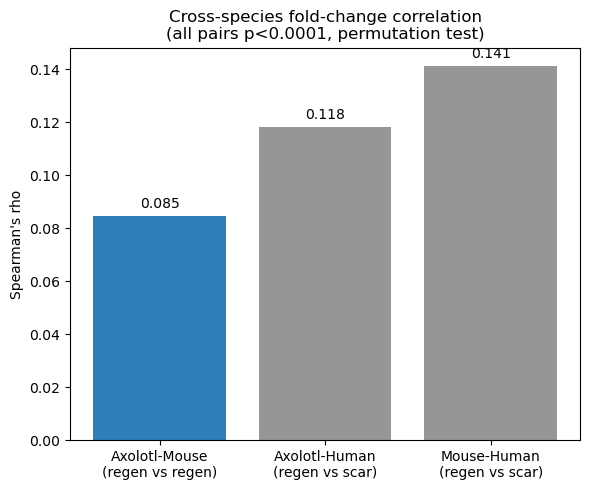

In [9]:
import matplotlib.pyplot as plt

fig, ax_ = plt.subplots(figsize=(6,5))
comparisons = ["Axolotl-Mouse\n(regen vs regen)", "Axolotl-Human\n(regen vs scar)", "Mouse-Human\n(regen vs scar)"]
rhos = [0.0845, 0.1181, 0.1410]
colors = ["#2c7fb8", "#969696", "#969696"]
bars = ax_.bar(comparisons, rhos, color=colors)
ax_.set_ylabel("Spearman's rho")
ax_.set_title("Cross-species fold-change correlation\n(all pairs p<0.0001, permutation test)")
for b, r in zip(bars, rhos):
    ax_.text(b.get_x()+b.get_width()/2, r+0.003, f"{r:.3f}", ha="center")
plt.tight_layout()
fig_dir = os.path.expanduser("~/FYP_Regeneration/results/figures/cross_species/")
plt.savefig(os.path.join(fig_dir, "specificity_comparison_bar.png"), dpi=300)
plt.show()

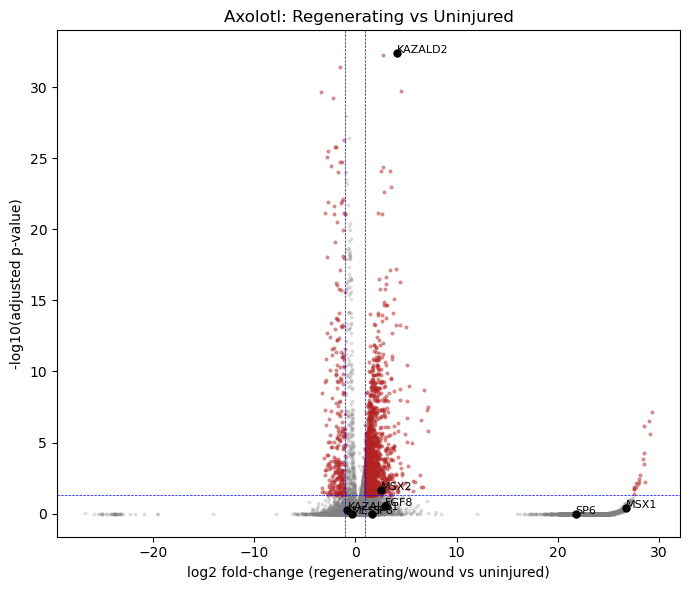

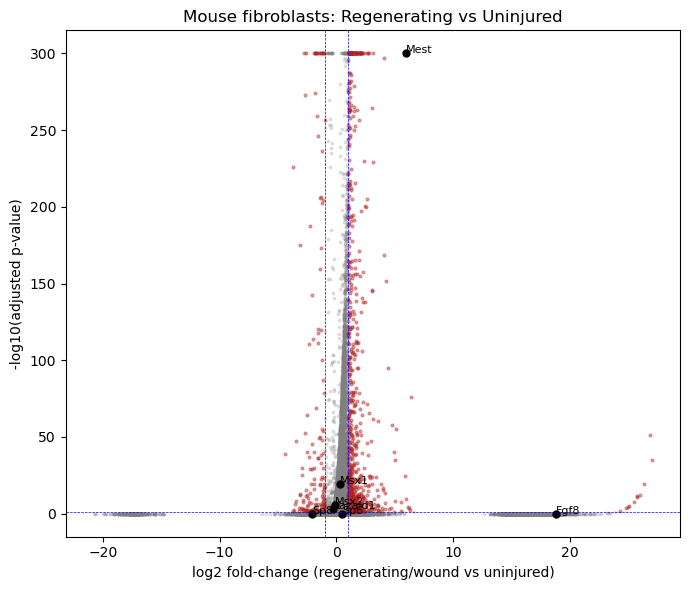

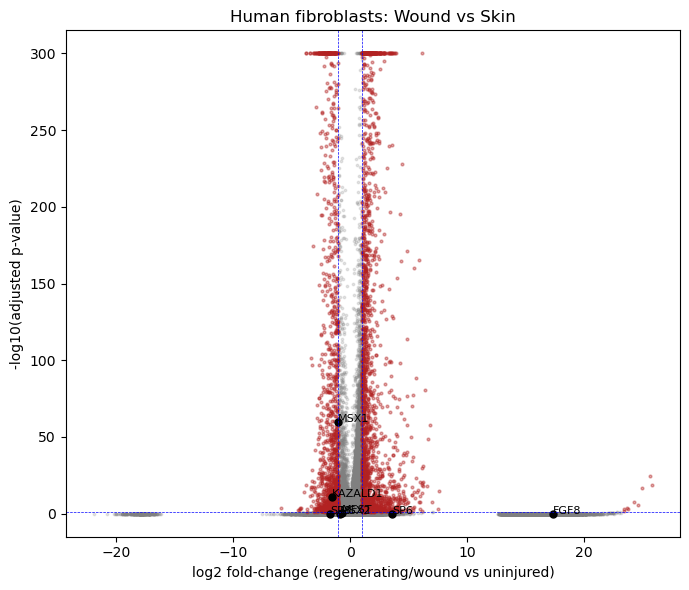

In [10]:
def volcano(df, title, fname, controls=None):
    df = df.copy()
    df["neglog10padj"] = -np.log10(df["pvals_adj"].clip(lower=1e-300))
    df["sig"] = (df["pvals_adj"]<0.05) & (df["logfoldchanges"].abs()>1)
    fig, ax_ = plt.subplots(figsize=(7,6))
    ax_.scatter(df.loc[~df["sig"],"logfoldchanges"], df.loc[~df["sig"],"neglog10padj"],
                s=3, alpha=0.2, color="grey")
    ax_.scatter(df.loc[df["sig"],"logfoldchanges"], df.loc[df["sig"],"neglog10padj"],
                s=4, alpha=0.4, color="firebrick")
    if controls:
        hit = df[df["gene"].astype(str).str.upper().isin(controls)]
        ax_.scatter(hit["logfoldchanges"], hit["neglog10padj"], s=25, color="black")
        for _, row in hit.iterrows():
            ax_.annotate(row["gene"], (row["logfoldchanges"], row["neglog10padj"]), fontsize=8)
    ax_.axhline(-np.log10(0.05), color="blue", lw=0.5, ls="--")
    ax_.axvline(1, color="blue", lw=0.5, ls="--")
    ax_.axvline(-1, color="blue", lw=0.5, ls="--")
    ax_.set_xlabel("log2 fold-change (regenerating/wound vs uninjured)")
    ax_.set_ylabel("-log10(adjusted p-value)")
    ax_.set_title(title)
    plt.tight_layout()
    plt.savefig(os.path.join(fig_dir, fname), dpi=300)
    plt.show()

controls = ["MEST","MSX1","MSX2","SP6","SP8","FGF8","KAZALD1","KAZALD2"]
volcano(ax_all if 'ax_all' in dir() else pd.read_csv(os.path.join(tables_dir,"axolotl_regen_vs_uninjured_all.csv")),
        "Axolotl: Regenerating vs Uninjured", "volcano_axolotl.png", controls)
volcano(pd.read_csv(os.path.join(tables_dir,"mouse_sc_fibroblast_regen_vs_uninjured_all.csv")),
        "Mouse fibroblasts: Regenerating vs Uninjured", "volcano_mouse.png", controls)
volcano(pd.read_csv(os.path.join(tables_dir,"human_fibroblast_wound_vs_skin_all.csv")),
        "Human fibroblasts: Wound vs Skin", "volcano_human.png", controls)

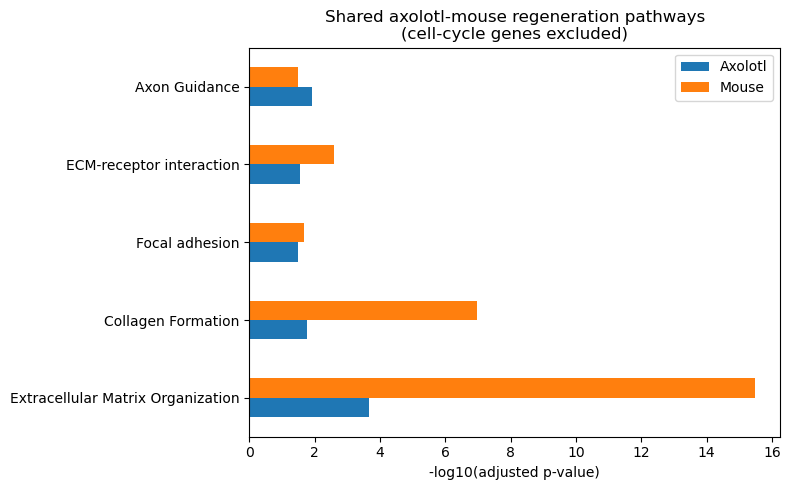

In [11]:
core_terms = ["Extracellular Matrix Organization R-HSA-1474244","Collagen Formation R-HSA-1474290",
              "Focal adhesion","ECM-receptor interaction","Axon Guidance R-HSA-422475"]
ax_p = pd.read_csv(os.path.join(tables_dir,"pathways_axolotl_noCC_FINAL.csv")).set_index("Term")
ms_p = pd.read_csv(os.path.join(tables_dir,"pathways_mouse_noCC_FINAL.csv")).set_index("Term")

plot_df = pd.DataFrame({
    "Axolotl": [-np.log10(ax_p.loc[t,"Adjusted P-value"]) if t in ax_p.index else 0 for t in core_terms],
    "Mouse": [-np.log10(ms_p.loc[t,"Adjusted P-value"]) if t in ms_p.index else 0 for t in core_terms],
}, index=[t.split(" R-HSA")[0] for t in core_terms])

plot_df.plot(kind="barh", figsize=(8,5))
plt.xlabel("-log10(adjusted p-value)")
plt.title("Shared axolotl-mouse regeneration pathways\n(cell-cycle genes excluded)")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "pathway_comparison_final.png"), dpi=300)
plt.show()

In [12]:
controls = ["MEST","MSX1","MSX2","SP6","SP8","FGF8","KAZALD1","KAZALD2"]
ax_all = pd.read_csv(os.path.join(tables_dir,"axolotl_regen_vs_uninjured_all.csv"))
ms_all = pd.read_csv(os.path.join(tables_dir,"mouse_sc_fibroblast_regen_vs_uninjured_all.csv"))
hu_all = pd.read_csv(os.path.join(tables_dir,"human_fibroblast_wound_vs_skin_all.csv"))

def grab(df, label):
    d = df[df["gene"].astype(str).str.upper().isin(controls)].copy()
    d["gene_upper"] = d["gene"].str.upper()
    d = d.set_index("gene_upper")[["logfoldchanges","pvals_adj"]]
    d.columns = [f"{label}_lfc", f"{label}_padj"]
    return d

combined = grab(ax_all,"axolotl").join(grab(ms_all,"mouse"), how="outer").join(grab(hu_all,"human"), how="outer")
combined.to_csv(os.path.join(tables_dir, "positive_controls_consolidated.csv"))
print(combined)

pd.DataFrame([
    {"test":"full_gene_set","rho":0.0845,"n":11544,"perm_p":"<0.0001"},
    {"test":"no_cell_cycle","rho":0.0772,"n":11454,"perm_p":"<0.0001"},
    {"test":"1to1_restricted","rho":0.0845,"n":11544,"perm_p":"<0.0001"},
]).to_csv(os.path.join(tables_dir, "axolotl_mouse_correlation_sensitivity_checks.csv"), index=False)
print("\nAll figures and tables saved.")

            axolotl_lfc  axolotl_padj  mouse_lfc    mouse_padj  human_lfc  \
gene_upper                                                                  
FGF8           2.938316  2.998825e-01  18.806390  1.000000e+00  17.340890   
KAZALD1       -0.778026  5.544944e-01  -0.294560  1.744519e-03  -1.585756   
KAZALD2        4.092959  4.242684e-33        NaN           NaN        NaN   
MEST          -0.355557  1.000000e+00   5.962614  0.000000e+00  -0.719229   
MSX1          26.699896  4.252603e-01   0.292499  2.614512e-20  -1.008320   
MSX2           2.502798  2.023412e-02  -0.124353  1.111324e-06  -0.867403   
SP6           21.755650  1.000000e+00   0.480141  1.000000e+00   3.575184   
SP8            1.654038  1.000000e+00  -2.094723  1.000000e+00  -1.716788   

              human_padj  
gene_upper                
FGF8        1.000000e+00  
KAZALD1     1.140386e-11  
KAZALD2              NaN  
MEST        3.506142e-01  
MSX1        9.413103e-61  
MSX2        1.000000e+00  
SP6         7

In [13]:
import os

fig_dir = os.path.expanduser("~/FYP_Regeneration/results/figures/cross_species/")
print("Folder exists:", os.path.exists(fig_dir))
print(f"\nContents of {fig_dir}:")
for f in sorted(os.listdir(fig_dir)):
    full = os.path.join(fig_dir, f)
    print(f"{os.path.getsize(full)/1024:8.1f} KB   {f}")

Folder exists: True

Contents of /home/ghayyas/FYP_Regeneration/results/figures/cross_species/:
   295.1 KB   axolotl_mouse_fc_correlation_v3.png
    34.4 KB   cross_species_ortholog_summary.png
   103.6 KB   pathway_comparison_final.png
   163.1 KB   pathway_enrichment_dotplot.png
    93.3 KB   specificity_comparison_bar.png
   179.5 KB   string_ppi_network.png
   263.8 KB   volcano_axolotl.png
   408.8 KB   volcano_human.png
   281.2 KB   volcano_mouse.png


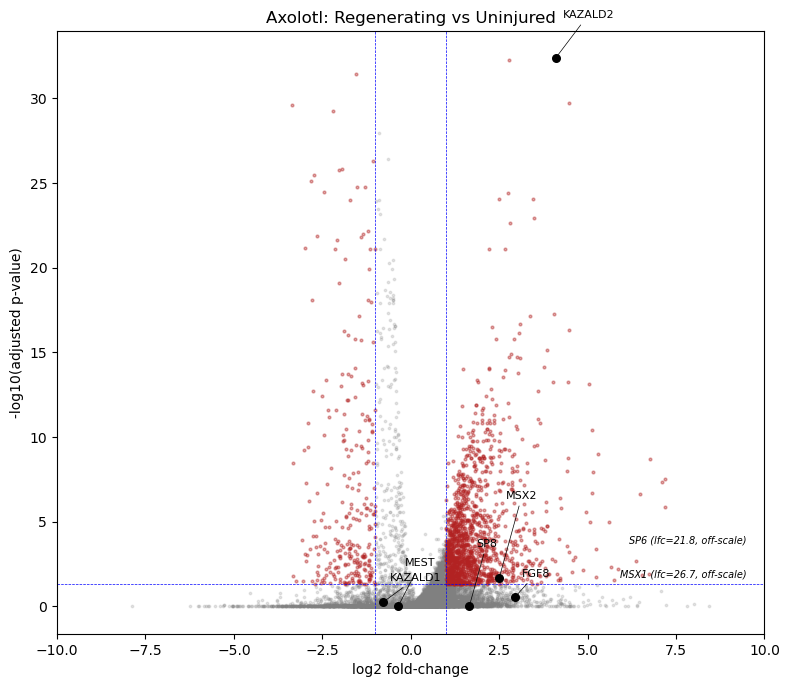

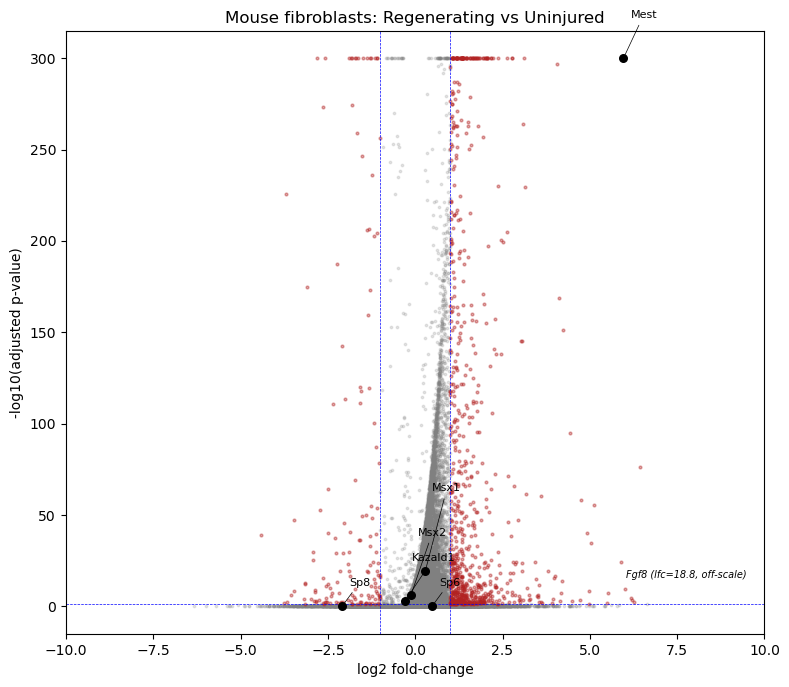

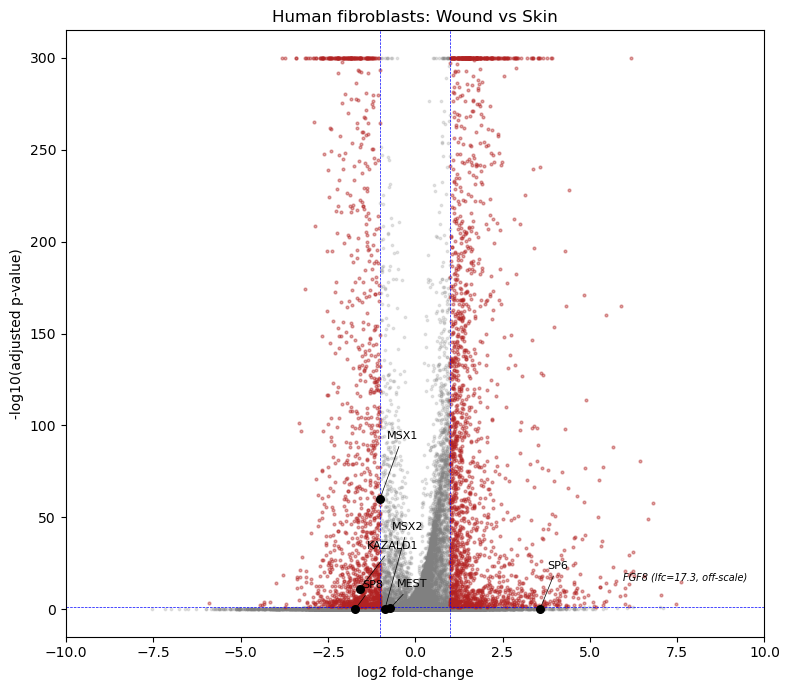

In [14]:
def volcano_v2(df, title, fname, controls=None, xlim=(-10,10), padj_floor=1e-300):
    df = df.copy()
    df["neglog10padj"] = -np.log10(df["pvals_adj"].clip(lower=padj_floor))
    df["sig"] = (df["pvals_adj"]<0.05) & (df["logfoldchanges"].abs()>1)
    fig, ax_ = plt.subplots(figsize=(8,7))
    ax_.scatter(df.loc[~df["sig"],"logfoldchanges"], df.loc[~df["sig"],"neglog10padj"],
                s=3, alpha=0.2, color="grey")
    ax_.scatter(df.loc[df["sig"],"logfoldchanges"], df.loc[df["sig"],"neglog10padj"],
                s=4, alpha=0.4, color="firebrick")

    if controls:
        hit = df[df["gene"].astype(str).str.upper().isin(controls)].copy()
        in_range = hit[hit["logfoldchanges"].between(*xlim)].sort_values("logfoldchanges")
        off_range = hit[~hit["logfoldchanges"].between(*xlim)]

        ax_.scatter(in_range["logfoldchanges"], in_range["neglog10padj"], s=30, color="black", zorder=5)
        for i, (_, row) in enumerate(in_range.iterrows()):
            ax_.annotate(row["gene"], (row["logfoldchanges"], row["neglog10padj"]),
                         xytext=(5, 15 + (i % 4) * 14), textcoords="offset points",
                         fontsize=8, arrowprops=dict(arrowstyle="-", lw=0.5, color="black"))

        for i, (_, row) in enumerate(off_range.iterrows()):
            edge_x = xlim[1]*0.95 if row["logfoldchanges"] > 0 else xlim[0]*0.95
            y_pos = (0.05 + i*0.06) * ax_.get_ylim()[1]
            ax_.annotate(f"{row['gene']} (lfc={row['logfoldchanges']:.1f}, off-scale)",
                         (edge_x, y_pos), fontsize=7, style="italic",
                         ha="right" if row["logfoldchanges"]>0 else "left")

    ax_.axhline(-np.log10(0.05), color="blue", lw=0.5, ls="--")
    ax_.axvline(1, color="blue", lw=0.5, ls="--")
    ax_.axvline(-1, color="blue", lw=0.5, ls="--")
    ax_.set_xlim(xlim)
    ax_.set_xlabel("log2 fold-change")
    ax_.set_ylabel("-log10(adjusted p-value)")
    ax_.set_title(title)
    plt.tight_layout()
    plt.savefig(os.path.join(fig_dir, fname), dpi=300)
    plt.show()

controls = ["MEST","MSX1","MSX2","SP6","SP8","FGF8","KAZALD1","KAZALD2"]
ax_all = pd.read_csv(os.path.join(tables_dir,"axolotl_regen_vs_uninjured_all.csv"))
ms_all = pd.read_csv(os.path.join(tables_dir,"mouse_sc_fibroblast_regen_vs_uninjured_all.csv"))
hu_all = pd.read_csv(os.path.join(tables_dir,"human_fibroblast_wound_vs_skin_all.csv"))

volcano_v2(ax_all, "Axolotl: Regenerating vs Uninjured", "volcano_axolotl_v2.png", controls)
volcano_v2(ms_all, "Mouse fibroblasts: Regenerating vs Uninjured", "volcano_mouse_v2.png", controls)
volcano_v2(hu_all, "Human fibroblasts: Wound vs Skin", "volcano_human_v2.png", controls)

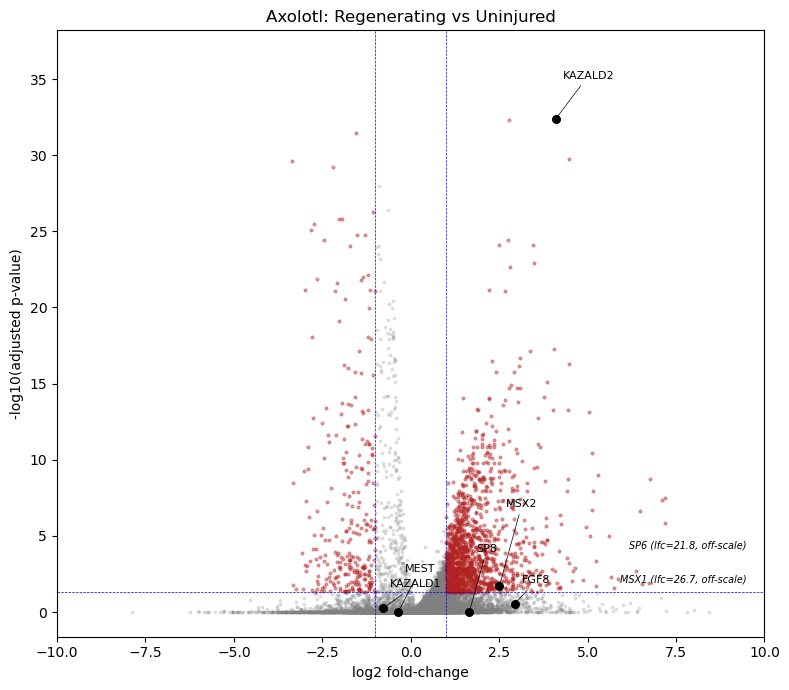

In [15]:
def volcano_v2(df, title, fname, controls=None, xlim=(-10,10), padj_floor=1e-300):
    df = df.copy()
    df["neglog10padj"] = -np.log10(df["pvals_adj"].clip(lower=padj_floor))
    df["sig"] = (df["pvals_adj"]<0.05) & (df["logfoldchanges"].abs()>1)
    fig, ax_ = plt.subplots(figsize=(8,7))
    ax_.scatter(df.loc[~df["sig"],"logfoldchanges"], df.loc[~df["sig"],"neglog10padj"],
                s=3, alpha=0.2, color="grey")
    ax_.scatter(df.loc[df["sig"],"logfoldchanges"], df.loc[df["sig"],"neglog10padj"],
                s=4, alpha=0.4, color="firebrick")

    # Add headroom so top labels don't collide with the title
    visible = df[df["logfoldchanges"].between(*xlim)]
    ymax = visible["neglog10padj"].max()
    ax_.set_ylim(top=ymax * 1.18)

    if controls:
        hit = df[df["gene"].astype(str).str.upper().isin(controls)].copy()
        in_range = hit[hit["logfoldchanges"].between(*xlim)].sort_values("logfoldchanges")
        off_range = hit[~hit["logfoldchanges"].between(*xlim)]

        ax_.scatter(in_range["logfoldchanges"], in_range["neglog10padj"], s=30, color="black", zorder=5)
        for i, (_, row) in enumerate(in_range.iterrows()):
            # push labels down instead of up when the point is in the top 15% of the plot
            y_frac = row["neglog10padj"] / ax_.get_ylim()[1]
            y_off = -18 if y_frac > 0.85 else 15 + (i % 4) * 14
            ax_.annotate(row["gene"], (row["logfoldchanges"], row["neglog10padj"]),
                         xytext=(5, y_off), textcoords="offset points",
                         fontsize=8, arrowprops=dict(arrowstyle="-", lw=0.5, color="black"))

        for i, (_, row) in enumerate(off_range.iterrows()):
            edge_x = xlim[1]*0.95 if row["logfoldchanges"] > 0 else xlim[0]*0.95
            y_pos = (0.05 + i*0.06) * ax_.get_ylim()[1]
            ax_.annotate(f"{row['gene']} (lfc={row['logfoldchanges']:.1f}, off-scale)",
                         (edge_x, y_pos), fontsize=7, style="italic",
                         ha="right" if row["logfoldchanges"]>0 else "left")

    ax_.axhline(-np.log10(0.05), color="blue", lw=0.5, ls="--")
    ax_.axvline(1, color="blue", lw=0.5, ls="--")
    ax_.axvline(-1, color="blue", lw=0.5, ls="--")
    ax_.set_xlim(xlim)
    ax_.set_xlabel("log2 fold-change")
    ax_.set_ylabel("-log10(adjusted p-value)")
    ax_.set_title(title)
    plt.tight_layout()
    plt.savefig(os.path.join(fig_dir, fname), dpi=300)
    plt.show()

volcano_v2(ax_all, "Axolotl: Regenerating vs Uninjured", "volcano_axolotl_v3.png", controls)